<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/1.%20Data%20download%20(WBS%3A%202.2%20%26%202.3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/notebooks/1%20Data%20Download%20%28WBS%202.2-2.3%29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1 Data Download

Daily prices for the 16 ETFs of both universes: download from Yahoo Finance, frozen copy with checksum, quality checks and the clean daily price table.

**Data:** daily open, high, low, close, adjusted close, volume, dividends, splits and capital gains, 2 January 2009 to 30 September 2026.

**Outputs** (`data` folder):

| File | Folder | Contents |
|---|---|---|
| Raw Prices.csv | raw | Download as received from Yahoo |
| Raw Prices Info.json | raw | Download time, settings, library versions and checksum |
| Quality Report.csv | reports | Result of every quality check |
| Daily Prices.parquet / .csv | processed | Clean daily prices |
| Filled Prices.csv | reports | Prices filled from the previous trading day |
| Coverage.csv | reports | One summary row per ETF |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: b0bbfdc, Wrong file (2026-10-30 14:13)



In [2]:
import importlib

import matplotlib.pyplot as plt
import yfinance as yf

from src import cleaning, config, download

# Reload after a fresh clone
for module in (config, download, cleaning):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()

# Download settings
print("Tickers:", len(config.ALL_TICKERS), config.ALL_TICKERS)
print("Period: ", config.START, "to", config.END, "(end date excluded)")
print("yfinance:", yf.__version__)

Tickers: 16 ['AGG', 'DBC', 'EEM', 'EFA', 'IWM', 'JPXN', 'QQQ', 'SPY', 'VTI', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLV', 'XLY']
Period:  2009-01-01 to 2026-10-01 (end date excluded)
yfinance: 1.7.0


## 2. Download and freeze

The prices are downloaded only when no frozen copy exists. `NEW_DOWNLOAD = True` replaces the frozen copy.

In [3]:
# True replaces the frozen download
NEW_DOWNLOAD = False

if download.is_frozen(DIRS["raw"]) and not NEW_DOWNLOAD:
    print("Frozen download found:", config.FILES["raw"])
else:
    prices_raw = download.download_prices()
    download.freeze(prices_raw, DIRS["raw"], overwrite=NEW_DOWNLOAD)

Frozen download found: Raw Prices.csv


## 3. Load the frozen download

The checksum of the price file is recomputed and compared with the recorded one.

In [4]:
# Fails if the checksum differs from the recorded one
prices, info = download.load_frozen(DIRS["raw"])
print("Downloaded:", info["downloaded_utc"], "with yfinance", info["versions"]["yfinance"])
prices.head()

Loaded Raw Prices.csv: 71,408 rows, 16 tickers, checksum verified
Downloaded: 2026-10-16T10:22:01+00:00 with yfinance 1.7.0


,date,ticker,open,high,low,close,adj_close,volume,dividends,splits,capital_gains
0,2009-01-02,AGG,103.750000,104.389999,103.500000,103.550003,61.980915,484600,0.0,0.0,0.0
1,2009-01-05,AGG,103.500000,105.320000,103.099998,105.199997,62.968513,3306400,0.0,0.0,0.0
2,2009-01-06,AGG,104.739998,104.870003,103.410004,104.610001,62.615356,670200,0.0,0.0,0.0
3,2009-01-07,AGG,104.209999,104.279999,103.260002,103.650002,62.040726,1222800,0.0,0.0,0.0
4,2009-01-08,AGG,103.910004,104.059998,102.599998,102.860001,61.567894,1616300,0.0,0.0,0.0


## 4. Quality checks

Each check reports PASS, WARN or FAIL; only non-PASS rows are printed. The notebook stops on any FAIL.

| Level | Checks |
|---|---|
| Table | Required columns, all tickers present, duplicate rows, stray dates, trading calendar |
| Ticker | Date order, coverage of the period, missing days, empty values, positive prices, high/low range, one-day moves above 25%, Close/Adj Close ratio, zero-volume days, stale prices |

In [5]:
report = cleaning.run_quality_checks(prices)
overall = cleaning.summarize(report)
# Full report, passed checks included
report.to_csv(DIRS["reports"] / config.FILES["quality"], index=False)

if overall == "FAIL":
    raise RuntimeError("A quality check failed.")

PASS 180   WARN 1   FAIL 0
      check ticker status                                                                                detail
zero volume   JPXN   WARN 30 days with volume 0: 2012-04-09, 2012-04-13, 2012-07-06, 2012-08-02, 2012-08-24 ...


## 5. Clean and save

All ETFs are placed on one trading calendar, single missing days are filled from the previous trading day and zero-volume days are flagged. Every ETF must then have a price at every month-end.

In [6]:
clean, fill_log = cleaning.clean_prices(prices)

# Every ETF needs a price at every month-end
month_end_report = cleaning.check_month_ends(clean)
cleaning.summarize(month_end_report)
if (month_end_report["status"] == "FAIL").any():
    raise RuntimeError("A month-end price is missing.")

# Clean prices and the fill log
cleaning.save_clean(clean, fill_log, DIRS["processed"], DIRS["reports"])
print(f"Prices filled from the previous day: {len(fill_log)}")

# Summary per ETF
coverage = cleaning.coverage_table(clean)
coverage.to_csv(DIRS["reports"] / config.FILES["coverage"], index=False)
coverage

PASS 16   WARN 0   FAIL 0
All checks passed.
Saved 71,408 rows to /content/drive/MyDrive/Capstone Main - Guyen/data/processed/Daily Prices.parquet
Prices filled from the previous day: 0


,ticker,universe,first_date,last_date,trading_days,filled_days,zero_volume_days,dividend_days,total_return
0,AGG,A,2009-01-02,2026-09-30,4463,0,0,212,0.520
1,DBC,A,2009-01-02,2026-09-30,4463,0,0,6,0.743
2,EEM,A,2009-01-02,2026-09-30,4463,0,0,39,2.671
3,EFA,A,2009-01-02,2026-09-30,4463,0,0,36,2.865
4,IWM,B,2009-01-02,2026-09-30,4463,0,0,71,6.018
5,JPXN,A,2009-01-02,2026-09-30,4463,0,30,35,2.428
6,QQQ,B,2009-01-02,2026-09-30,4463,0,0,74,26.678
7,SPY,A and B,2009-01-02,2026-09-30,4463,0,0,71,10.275
8,VTI,A,2009-01-02,2026-09-30,4463,0,0,71,10.124
9,XLE,B,2009-01-02,2026-09-30,4463,0,0,72,3.317


## 6. Growth of $1

Adjusted prices relative to the first trading day, on a log scale. A vertical jump that matches no market event indicates a faulty adjustment.

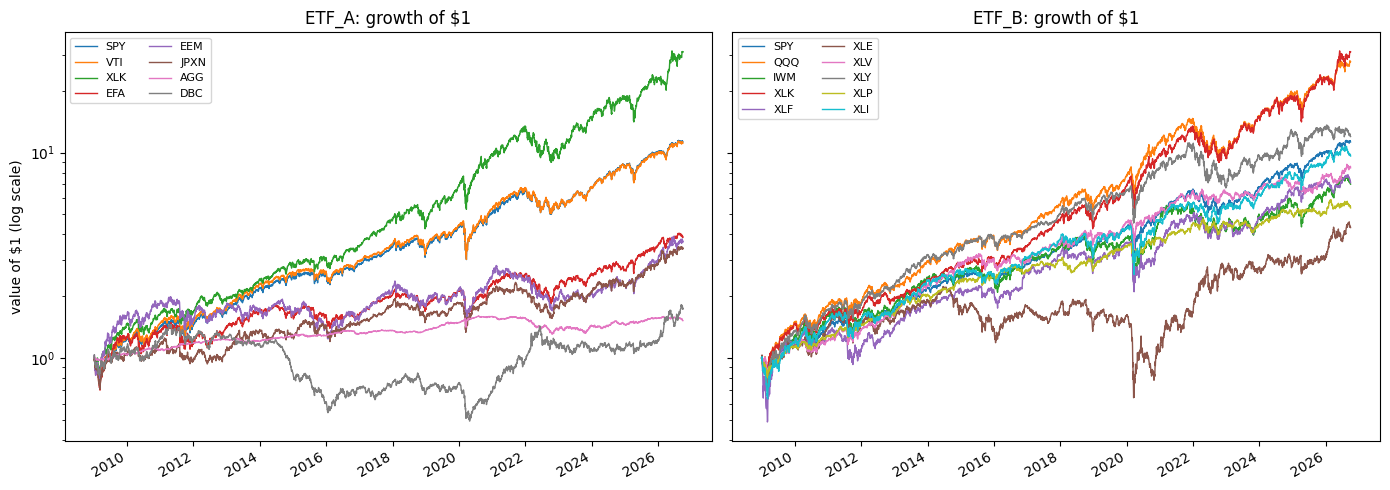

In [7]:
# Adjusted price relative to the first trading day
adj = clean.pivot(index="date", columns="ticker", values="adj_close")
growth = adj / adj.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, tickers) in zip(axes, [("ETF_A", config.ETF_A), ("ETF_B", config.ETF_B)]):
    growth[tickers].plot(ax=ax, logy=True, linewidth=1)
    ax.set_title(f"{name}: growth of $1")
    ax.set_xlabel("")
    ax.legend(ncol=2, fontsize=8)
axes[0].set_ylabel("value of $1 (log scale)")
plt.tight_layout()
plt.show()

## 7. Summary

In [8]:
# Key figures
print(f"Raw file:      {config.FILES['raw']}")
print(f"Checksum:      {info['md5']}")
print(f"Downloaded:    {info['downloaded_utc']}")
print(f"Rows:          {len(clean):,}")
print(f"Trading days:  {clean['date'].nunique():,}")
print(f"Month-ends:    {len(cleaning.month_end_dates(clean))}")
print(f"Checks:        {overall}, prices filled: {len(fill_log)}")

Raw file:      Raw Prices.csv
Checksum:      80113beee459649ee81eda775e0eee79
Downloaded:    2026-10-16T10:22:01+00:00
Rows:          71,408
Trading days:  4,463
Month-ends:    213
Checks:        WARN, prices filled: 0
